# Final Model Fitting and Evaluation

## Objective and evaluation contract

This notebook finalizes the multiclass prediction of **Home Win**, **Draw**, and **Away Win**.

1. Fit only on 2010/11–2013/14 training rows.
2. Compare feature sets, models, and hyperparameters only on the 2014/15 validation season.
3. Lock the feature set, model family, imbalance treatment, and hyperparameters.
4. Load and evaluate the 2015/16 test season only after those decisions are fixed.

Macro F1 is the primary metric; accuracy and class-level F1 are secondary evidence. No shuffled cross-validation is used because future seasons must not inform earlier fits.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight

sns.set_theme(style="whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate data/processed from the current directory.")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CLASS_ORDER = ["Home Win", "Draw", "Away Win"]
PRIMARY_METRIC = "validation_macro_f1"

## 1. Load training and validation only

The test file is deliberately not loaded in this stage. Every comparison below fits on training data and scores the designated chronological validation holdout.

In [2]:
train_data = pd.read_csv(PROCESSED_DIR / "train_processed.csv")
validation_data = pd.read_csv(PROCESSED_DIR / "validation_processed.csv")

assert train_data.columns.equals(validation_data.columns)
assert "target" in train_data.columns

all_features = train_data.columns.drop("target").tolist()
top_40_features = pd.read_csv(
    TABLES_DIR / "selected_top40_features.csv"
)["feature"].tolist()

assert len(all_features) == 80
assert len(top_40_features) == 40
assert set(top_40_features).issubset(all_features)

y_train = train_data["target"].copy()
y_val = validation_data["target"].copy()
balanced_train_weights = compute_sample_weight(class_weight="balanced", y=y_train)

development_summary = pd.DataFrame(
    {
        "split": ["Training (2010/11–2013/14)", "Validation (2014/15)"],
        "matches": [len(train_data), len(validation_data)],
        "processed_features": [len(all_features), len(all_features)],
        "missing_values": [
            int(train_data.isna().sum().sum()),
            int(validation_data.isna().sum().sum()),
        ],
    }
)
display(development_summary)

,split,matches,processed_features,missing_values
0,Training (2010/11–2013/14),11413,80,0
1,Validation (2014/15),3067,80,0


## 2. Resolve Top 40 versus all processed features

The same balanced Gradient Boosting configuration is fitted twice. Only the feature set changes. A smaller set is preferred whenever all features do not produce a meaningful validation Macro F1 improvement; a threshold of 0.005 (half a percentage point) is declared before comparison.

In [3]:
BASELINE_PARAMS = {
    "n_estimators": 150,
    "learning_rate": 0.05,
    "max_depth": 3,
    "min_samples_leaf": 1,
    "subsample": 1.0,
    "random_state": RANDOM_STATE,
}
PRACTICAL_IMPROVEMENT = 0.005
feature_set_rows = []

for feature_set_name, features in [
    ("Top 40", top_40_features),
    ("All 80", all_features),
]:
    candidate = GradientBoostingClassifier(**BASELINE_PARAMS)
    candidate.fit(
        train_data[features],
        y_train,
        sample_weight=balanced_train_weights,
    )
    predictions = candidate.predict(validation_data[features])
    class_f1 = f1_score(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        average=None,
        zero_division=0,
    )
    feature_set_rows.append(
        {
            "feature_set": feature_set_name,
            "feature_count": len(features),
            "validation_macro_f1": f1_score(y_val, predictions, average="macro"),
            "validation_accuracy": accuracy_score(y_val, predictions),
            **{f"{label}_f1": score for label, score in zip(CLASS_ORDER, class_f1)},
        }
    )

feature_set_comparison = pd.DataFrame(feature_set_rows)
feature_set_comparison.to_csv(
    TABLES_DIR / "gradient_boosting_feature_set_comparison.csv",
    index=False,
)
display(feature_set_comparison.round(4))

top_40_score = feature_set_comparison.loc[
    feature_set_comparison["feature_set"] == "Top 40", "validation_macro_f1"
].iloc[0]
all_feature_score = feature_set_comparison.loc[
    feature_set_comparison["feature_set"] == "All 80", "validation_macro_f1"
].iloc[0]
all_feature_gain = all_feature_score - top_40_score

if all_feature_gain > PRACTICAL_IMPROVEMENT:
    selected_feature_set = "All 80"
    selected_features = all_features
else:
    selected_feature_set = "Top 40"
    selected_features = top_40_features

display(Markdown(
    f"**Decision:** retain **{selected_feature_set}**. All features changed validation "
    f"Macro F1 by `{all_feature_gain:+.4f}` relative to Top 40; this does not exceed "
    f"the predeclared `{PRACTICAL_IMPROVEMENT:.3f}` meaningful-improvement threshold."
))

,feature_set,feature_count,validation_macro_f1,validation_accuracy,Home Win_f1,Draw_f1,Away Win_f1
0,Top 40,40,0.4570,0.4764,0.5811,0.3020,0.4879
1,All 80,80,0.4545,0.4738,0.5741,0.2984,0.4910


**Decision:** retain **Top 40**. All features changed validation Macro F1 by `-0.0025` relative to Top 40; this does not exceed the predeclared `0.005` meaningful-improvement threshold.

## 3. Final method-family comparison

Completed, defensible alternatives are compared on the chosen features. Linear SVM is scaled using training-fitted parameters. Tree ensembles use unscaled inputs. Balanced class/sample weighting is used where supported; unfinished optional experiments are outside the final comparison.

In [4]:
X_train = train_data[selected_features]
X_val = validation_data[selected_features]
validation_rows = []


def record_validation(model_name, predictions):
    class_f1 = f1_score(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        average=None,
        zero_division=0,
    )
    validation_rows.append(
        {
            "model": model_name,
            "validation_accuracy": accuracy_score(y_val, predictions),
            "validation_macro_f1": f1_score(y_val, predictions, average="macro"),
            **{f"{label}_f1": score for label, score in zip(CLASS_ORDER, class_f1)},
        }
    )


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
linear_svm = LinearSVC(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    max_iter=10_000,
)
linear_svm.fit(X_train_scaled, y_train)
record_validation("Linear SVM", linear_svm.predict(X_val_scaled))

extra_trees = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
extra_trees.fit(X_train, y_train)
record_validation("Extra Trees", extra_trees.predict(X_val))

hist_gradient_boosting = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    random_state=RANDOM_STATE,
)
hist_gradient_boosting.fit(
    X_train,
    y_train,
    sample_weight=balanced_train_weights,
)
record_validation(
    "HistGradientBoosting",
    hist_gradient_boosting.predict(X_val),
)

gradient_boosting = GradientBoostingClassifier(**BASELINE_PARAMS)
gradient_boosting.fit(
    X_train,
    y_train,
    sample_weight=balanced_train_weights,
)
record_validation("Gradient Boosting", gradient_boosting.predict(X_val))

validation_comparison = (
    pd.DataFrame(validation_rows)
    .sort_values(["validation_macro_f1", "validation_accuracy"], ascending=False)
    .reset_index(drop=True)
)
validation_comparison.insert(0, "rank", range(1, len(validation_comparison) + 1))
validation_comparison.to_csv(
    TABLES_DIR / "final_model_validation_comparison.csv",
    index=False,
)
display(validation_comparison.round(4))

assert validation_comparison.loc[0, "model"] == "Gradient Boosting"

,rank,model,validation_accuracy,validation_macro_f1,Home Win_f1,Draw_f1,Away Win_f1
0,1,Gradient Boosting,0.4764,0.4570,0.5811,0.3020,0.4879
1,2,HistGradientBoosting,0.4744,0.4524,0.5787,0.2883,0.4902
2,3,Linear SVM,0.4995,0.3922,0.6248,0.0491,0.5027
3,4,Extra Trees,0.5155,0.3815,0.6475,0.0264,0.4707


## 4. Reproducible Gradient Boosting tuning

`ParameterSampler` selects exactly 20 configurations with `random_state=42` from the declared modest search space. Every model fits **only training rows** with balanced sample weights and is scored on the 2014/15 validation holdout. The 2015/16 test file remains unopened.

Configurations are ranked by validation Macro F1, then by simpler structure (`n_estimators`, `max_depth`, and larger `min_samples_leaf`), and finally validation accuracy.

,rank,configuration_id,subsample,n_estimators,min_samples_leaf,max_depth,learning_rate,validation_macro_f1,validation_accuracy,Home Win_f1,Draw_f1,Away Win_f1
0,1,16,1.0,250,5,2,0.050,0.4636,0.4813,0.5809,0.3164,0.4936
1,2,8,1.0,150,10,2,0.030,0.4604,0.4777,0.5790,0.3112,0.4910
2,3,9,0.9,250,10,3,0.030,0.4597,0.4783,0.5818,0.3099,0.4873
3,4,20,0.8,250,1,2,0.050,0.4594,0.4767,0.5801,0.3112,0.4868
4,5,18,0.9,200,1,3,0.030,0.4585,0.4760,0.5786,0.3125,0.4845
5,6,14,1.0,200,5,3,0.075,0.4562,0.4770,0.5826,0.3022,0.4838
6,7,10,1.0,200,20,3,0.075,0.4544,0.4754,0.5805,0.3015,0.4813
7,8,1,0.8,200,20,3,0.050,0.4537,0.4738,0.5763,0.2978,0.4872
8,9,11,1.0,100,20,2,0.100,0.4515,0.4705,0.5735,0.2920,0.4890
9,10,13,1.0,150,20,4,0.050,0.4506,0.4698,0.5716,0.3028,0.4774


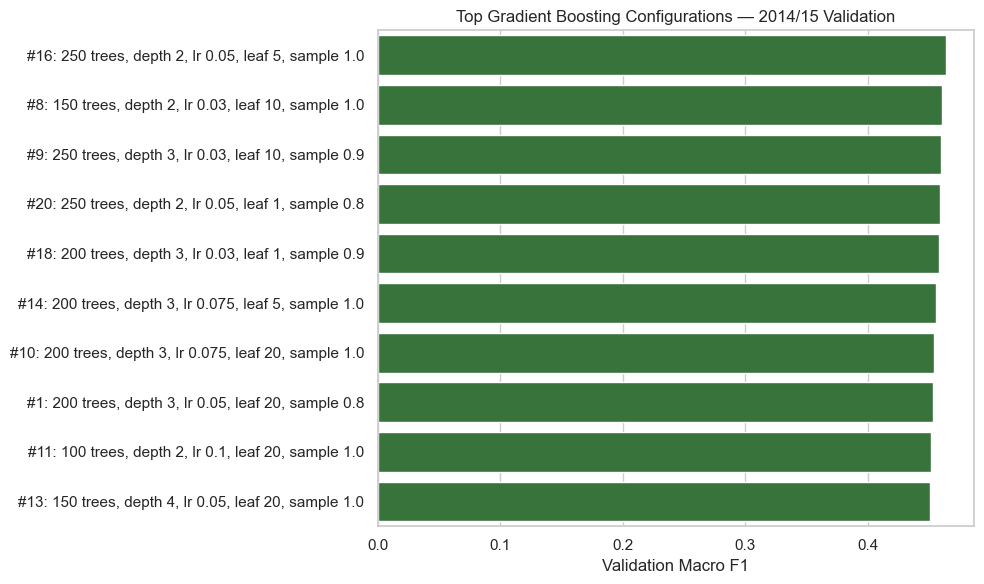

In [5]:
PARAMETER_SPACE = {
    "n_estimators": [100, 150, 200, 250],
    "learning_rate": [0.03, 0.05, 0.075, 0.10],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [1, 5, 10, 20],
    "subsample": [0.8, 0.9, 1.0],
}
sampled_parameters = list(
    ParameterSampler(PARAMETER_SPACE, n_iter=20, random_state=RANDOM_STATE)
)
tuning_rows = []

for configuration_id, parameters in enumerate(sampled_parameters, start=1):
    candidate = GradientBoostingClassifier(
        **parameters,
        random_state=RANDOM_STATE,
    )
    candidate.fit(X_train, y_train, sample_weight=balanced_train_weights)
    predictions = candidate.predict(X_val)
    class_f1 = f1_score(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        average=None,
        zero_division=0,
    )
    tuning_rows.append(
        {
            "configuration_id": configuration_id,
            **parameters,
            "validation_macro_f1": f1_score(y_val, predictions, average="macro"),
            "validation_accuracy": accuracy_score(y_val, predictions),
            **{f"{label}_f1": score for label, score in zip(CLASS_ORDER, class_f1)},
        }
    )

tuning_results = (
    pd.DataFrame(tuning_rows)
    .sort_values(
        [
            "validation_macro_f1",
            "n_estimators",
            "max_depth",
            "min_samples_leaf",
            "validation_accuracy",
        ],
        ascending=[False, True, True, False, False],
    )
    .reset_index(drop=True)
)
tuning_results.insert(0, "rank", range(1, len(tuning_results) + 1))
tuning_results.to_csv(
    TABLES_DIR / "gradient_boosting_tuning_results.csv",
    index=False,
)
tuning_results.head(10).to_csv(
    TABLES_DIR / "gradient_boosting_tuning_summary.csv",
    index=False,
)
display(tuning_results.head(10).round(4))

best_row = tuning_results.iloc[0]
best_params = {
    "n_estimators": int(best_row["n_estimators"]),
    "learning_rate": float(best_row["learning_rate"]),
    "max_depth": int(best_row["max_depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
    "subsample": float(best_row["subsample"]),
    "random_state": RANDOM_STATE,
}

top_tuning = tuning_results.head(10).copy()
top_tuning["configuration"] = top_tuning.apply(
    lambda row: (
        f"#{int(row['configuration_id'])}: {int(row['n_estimators'])} trees, "
        f"depth {int(row['max_depth'])}, lr {row['learning_rate']}, "
        f"leaf {int(row['min_samples_leaf'])}, sample {row['subsample']}"
    ),
    axis=1,
)
fig, axis = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_tuning,
    x="validation_macro_f1",
    y="configuration",
    color="#2E7D32",
    ax=axis,
)
axis.set_title("Top Gradient Boosting Configurations — 2014/15 Validation")
axis.set_xlabel("Validation Macro F1")
axis.set_ylabel("")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "gradient_boosting_tuning_results.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 5. Lock final decisions before test access

At this point the final feature set, model family, class-imbalance treatment, and hyperparameters are fixed from training/validation evidence. The next cell records the immutable modelling contract before the test file is loaded.

In [6]:
locked_decision = {
    "model": "GradientBoostingClassifier",
    "feature_set": selected_feature_set,
    "feature_count": len(selected_features),
    "imbalance_treatment": "balanced sample weights",
    "selection_metric": "validation Macro F1",
    "training_seasons": "2010/11–2013/14",
    "validation_season": "2014/15",
    "test_season": "2015/16",
    **best_params,
}
locked_validation_macro_f1 = float(best_row["validation_macro_f1"])
locked_validation_accuracy = float(best_row["validation_accuracy"])

display(pd.DataFrame([locked_decision]).T.rename(columns={0: "locked_value"}))
display(Markdown(
    f"**Locked validation result:** Macro F1 `{locked_validation_macro_f1:.4f}`, "
    f"accuracy `{locked_validation_accuracy:.4f}`."
))

,locked_value
model,GradientBoostingClassifier
feature_set,Top 40
feature_count,40
imbalance_treatment,balanced sample weights
selection_metric,validation Macro F1
training_seasons,2010/11–2013/14
validation_season,2014/15
test_season,2015/16
n_estimators,250
learning_rate,0.05


**Locked validation result:** Macro F1 `0.4636`, accuracy `0.4813`.

## 6. One-time final test evaluation

**The test season was not used for model selection or hyperparameter tuning.**

Only now is `test_processed.csv` loaded. The locked model is refitted on training plus validation data, using recalculated balanced sample weights, and evaluated once on 2015/16.

,metric,value
0,Accuracy,0.4545
1,Macro F1,0.4410
2,Weighted F1,0.4618


,label,precision,recall,f1-score,support
0,Home Win,0.5973,0.5058,0.5477,1378.0000
1,Draw,0.2817,0.3471,0.3110,801.0000
2,Away Win,0.4585,0.4705,0.4644,950.0000
3,accuracy,0.4545,0.4545,0.4545,0.4545
4,macro avg,0.4458,0.4411,0.4410,3129.0000
5,weighted avg,0.4743,0.4545,0.4618,3129.0000


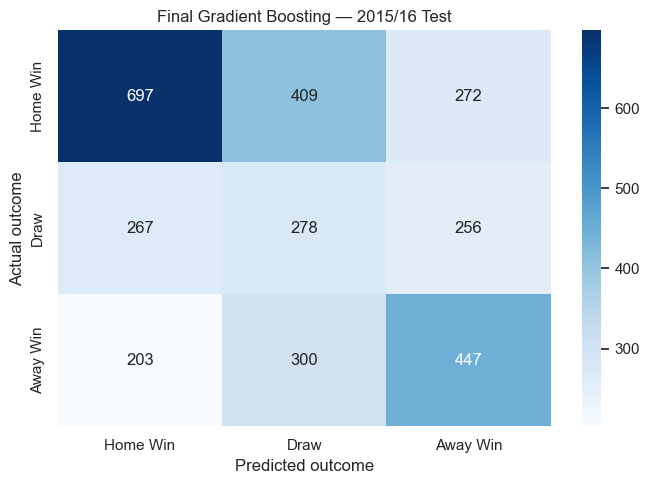

In [7]:
test_data = pd.read_csv(PROCESSED_DIR / "test_processed.csv")
assert test_data.columns.equals(train_data.columns)
assert set(selected_features).issubset(test_data.columns)

X_final_train = pd.concat(
    [train_data[selected_features], validation_data[selected_features]],
    ignore_index=True,
)
y_final_train = pd.concat([y_train, y_val], ignore_index=True)
X_test = test_data[selected_features]
y_test = test_data["target"].copy()
final_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_final_train,
)

final_model = GradientBoostingClassifier(**best_params)
final_model.fit(
    X_final_train,
    y_final_train,
    sample_weight=final_sample_weights,
)
final_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, final_predictions)
test_macro_f1 = f1_score(y_test, final_predictions, average="macro")
test_weighted_f1 = f1_score(y_test, final_predictions, average="weighted")

final_test_metrics = pd.DataFrame(
    {
        "metric": ["Accuracy", "Macro F1", "Weighted F1"],
        "value": [test_accuracy, test_macro_f1, test_weighted_f1],
    }
)
final_classification_report = (
    pd.DataFrame(
        classification_report(
            y_test,
            final_predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0,
        )
    )
    .T.rename_axis("label")
    .reset_index()
)

display(final_test_metrics.round(4))
display(final_classification_report.round(4))

final_confusion = confusion_matrix(y_test, final_predictions, labels=CLASS_ORDER)
fig, axis = plt.subplots(figsize=(7, 5))
sns.heatmap(
    final_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    ax=axis,
)
axis.set_title("Final Gradient Boosting — 2015/16 Test")
axis.set_xlabel("Predicted outcome")
axis.set_ylabel("Actual outcome")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "final_supervised_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 7. Interpretation and exports

The class-level report is essential: football outcomes remain noisy and Draw is the most difficult class. The model is an analytical benchmark, not a guarantee for individual fixtures. Feature importance measures predictive contribution within this fitted ensemble and does not establish causality.

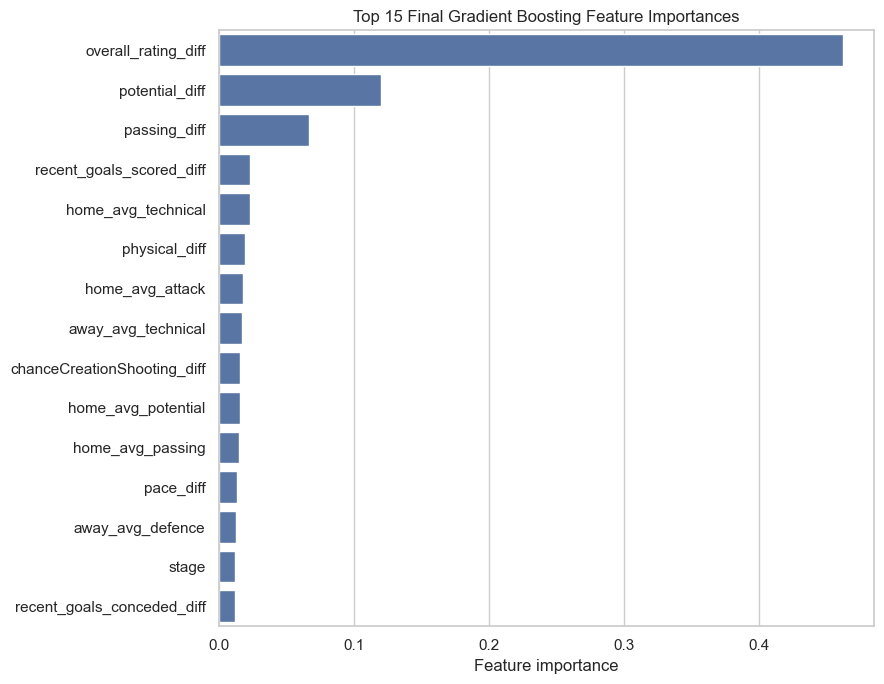

### Final result

The locked balanced Gradient Boosting model achieved test Macro F1 **0.4410**, accuracy **0.4545**, and weighted F1 **0.4618** on 2015/16. These values are reported after a single final evaluation under the documented chronological protocol.

In [8]:
final_importance = (
    pd.DataFrame(
        {
            "feature": selected_features,
            "importance": final_model.feature_importances_,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

fig, axis = plt.subplots(figsize=(9, 7))
sns.barplot(
    data=final_importance.head(15),
    x="importance",
    y="feature",
    color="#4C72B0",
    ax=axis,
)
axis.set_title("Top 15 Final Gradient Boosting Feature Importances")
axis.set_xlabel("Feature importance")
axis.set_ylabel("")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "final_model_feature_importance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

final_test_metrics.to_csv(
    TABLES_DIR / "final_supervised_test_metrics.csv",
    index=False,
)
final_classification_report.to_csv(
    TABLES_DIR / "final_supervised_classification_report.csv",
    index=False,
)
pd.DataFrame(
    {"setting": locked_decision.keys(), "value": locked_decision.values()}
).to_csv(
    TABLES_DIR / "final_supervised_model_config.csv",
    index=False,
)
final_importance.to_csv(
    TABLES_DIR / "final_model_feature_importance.csv",
    index=False,
)

display(Markdown(
    f"### Final result\n\n"
    f"The locked balanced Gradient Boosting model achieved test Macro F1 "
    f"**{test_macro_f1:.4f}**, accuracy **{test_accuracy:.4f}**, and weighted F1 "
    f"**{test_weighted_f1:.4f}** on 2015/16. These values are reported after a "
    "single final evaluation under the documented chronological protocol."
))